# 01 – Data exploration: HASH STI Question & Answer dataset

**Dataset:** *The HASH Sexually Transmitted Infection Question and Answer Crowdsourced Dataset* (2026),
Dataset Club, HASH (Infectious Diseases Institute, Makerere AI Lab and Sunbird AI).
DOI [10.7910/DVN/5SWM5U](https://doi.org/10.7910/DVN/5SWM5U). License **CC BY-NC 4.0**.

**What the dataset page says:** 5,488 Q&A pairs; 8 categories; each pair organised by *intent*
and mapped to two responses (simple and detailed).

**Goal of this notebook:** check what is really in the file before building anything:
1. File structure (sheets, columns, how intents are laid out)
2. Counts: questions, intents, questions per intent, categories
3. How answers are attached to intents
4. Missing values, answer lengths
5. Exact and near-duplicate questions
6. Personal/demographic columns
7. What this means for the train/val/test split

Run `python -m src.download_data` first. This notebook only reads the data.

In [1]:
import os
import random
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

PROJECT_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_ROOT)          # so relative paths like data/raw/... work
sys.path.insert(0, PROJECT_ROOT)
from src.load_raw import load_raw_sheets, questions_long

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FIG_DIR = "results/figures"
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 200)

## 1. File structure
The Excel file has one sheet per category. We print each sheet's original headers and size.

In [2]:
sheets = pd.read_excel("data/raw/hash_sti_qa.xlsx", sheet_name=None)
for name, df in sheets.items():
    print(f"{name:<15} rows={len(df):>4}  columns={list(df.columns)}")

General STIs    rows= 172  columns=['STIs_Chatbot_Intents', 'Unnamed: 1', 'Question from Crowdsourcing', 'Another Questions (the different ways the same question can be asked)', 'Simple Answer', 'Long Answer']
Gonorrhea       rows= 408  columns=['Gonorrhea_Chatbot_Intents', 'Unnamed: 1', 'Questions from Crowdsourcing', 'Another Questions (the different ways the same question can be asked)', 'Simple Answer', 'Long Answer']
Hepatitis B     rows= 341  columns=['Hepatitis_Chatbot_Intents', 'Unnamed: 1', 'Questions from Crowdsourcing', 'Another Questions (the different ways the same question can be asked)', 'Simple Answer', 'Long Answer']
HIV             rows= 280  columns=['HIV_Chatbot_Intents', 'Unnamed: 1', 'Question from Crowdsourcing', 'Another Questions (the different ways the same question can be asked)', 'Simple Answer', 'Long Answer']
Herpes          rows= 620  columns=['Herpes_simplex_virus_Chatbot Intents', 'Unnamed: 1', 'Questions from Crowdsourcing', 'Another Questions (the dif

In [3]:
raw = load_raw_sheets()       # all sheets stacked, columns renamed, intent forward-filled
print("Shape:", raw.shape)
raw.dtypes

Shape: (2951, 9)


category            str
excel_row         int64
intent              str
unnamed          object
q_crowd             str
q_other             str
simple_answer       str
long_answer         str
intent_block        str
dtype: object

### How an intent block looks
The intent label is written only on the first row of a block. Questions continue on the rows below.
Below is one block exactly as it appears in Excel (cells shortened to 70 characters).

In [4]:
def show_block(category, intent):
    block = raw[(raw["category"] == category) & (raw["intent_block"] == intent)]
    cols = ["excel_row", "intent", "unnamed", "q_crowd", "q_other", "simple_answer", "long_answer"]
    return block[cols].apply(lambda col: col.astype(str).str[:70].where(col.notna(), ""))

show_block("Syphilis", "Transmission/Spread_syphilis")

,excel_row,intent,unnamed,q_crowd,q_other,simple_answer,long_answer
2774,140,Transmission/Spread_syphilis,,,Do babies get Syphilis?,"Syphilis is transmitted during oral, anal or vaginal sex through conta","Syphilis is contagious, especially in the primary and secondary stages"
2775,141,,,,Who gets congenital Syphilis?,Babies born to mothers who have untreated syphilis are at risk of gett,Congenital syphilis is when your baby is born infected with syphilis.
2776,142,,,,"If I am pregnant and I have Syphilis, can my baby get it?",,
2777,143,,,,Does Syphilis run in the family?,"Syphilis is a sexually transmitted infection, it is not a genetic cond","Syphilis is an STI, it does not run in families genetically, however,"
2778,144,,,,Is Syphilis genetic?,,
2779,145,,,,Can I get Syphilis from sharing toilets?,"No, syphilis can not be spread through sharing toilets","Syphilis does not spread through sharing the toilets, syphilis spreads"
2780,146,,,,Can I get Syphilis from kissing?,"Yes. While it’s rare to get syphilis from kissing, you can get syphili",Syphilis is sexually transmitted through contact with a person who has
2781,147,,,,Is Syphilis sexually transmitted?,You can get syphilis by having direct contact with a syphilis sore. Th,Syphilis develops in stages. The symptoms vary with each stage. But th
2782,148,,,,How long am I contagious if I get Syphilis?,,
2783,149,,,,Where can you get Syphilis from?,,


## 2. Basic counts

In [5]:
q = questions_long(raw)   # one row per question cell

summary = pd.DataFrame({
    "excel_rows": raw.groupby("category").size(),
    "empty_rows": raw.drop(columns=["category", "excel_row", "intent_block"]).isna().all(axis=1).groupby(raw["category"]).sum(),
    "intent_labels": raw.groupby("category")["intent"].count(),
    "unique_intent_labels": raw.groupby("category")["intent"].nunique(),
    "questions": q.groupby("category").size(),
    "q_crowdsourced_col": q[q.question_source == "crowdsourced"].groupby("category").size(),
    "q_another_way_col": q[q.question_source == "another_way"].groupby("category").size(),
    "simple_answers": raw.groupby("category")["simple_answer"].count(),
    "long_answers": raw.groupby("category")["long_answer"].count(),
}).fillna(0).astype(int)
summary.loc["TOTAL"] = summary.sum()
summary

,excel_rows,empty_rows,intent_labels,unique_intent_labels,questions,q_crowdsourced_col,q_another_way_col,simple_answers,long_answers
category,,,,,,,,,
Chlamydia,490,39,15,15,451,2,449,52,43
General STIs,172,39,15,15,125,78,47,41,43
Gonorrhea,408,22,20,19,382,4,378,77,50
HIV,280,34,14,14,262,52,210,42,44
Hepatitis B,341,44,13,13,324,56,268,23,31
Herpes,620,66,13,13,553,2,551,67,60
Syphilis,315,77,13,13,234,3,231,62,49
Trichomoniasis,325,47,13,13,300,35,265,17,17
TOTAL,2951,368,116,115,2631,232,2399,381,337


In [6]:
print("Total question cells:", len(q))
print("Dataset page says   : 5,488 Q&A pairs")

Total question cells: 2631
Dataset page says   : 5,488 Q&A pairs


### Cells that contain several questions (line breaks)

In [7]:
multi = q[q["question"].astype(str).str.contains("\n")]
print("Question cells with line breaks:", len(multi))
print("Lines inside those cells       :", multi["question"].str.split("\n").str.len().sum())
multi.assign(question=multi["question"].str[:200])

Question cells with line breaks: 4
Lines inside those cells       : 46


,category,excel_row,intent_block,question,question_source
2375,Chlamydia,459,complications_chlamydia,What are the complications of chlamydia?\nWhat are the long term effects of chlamydia?\nWhat type of complications m...,another_way
1673,Herpes,603,complications_infections,What are the complications of Herpes?\nWhat are the long term effects of Herpes?\nAre there any complications of Her...,another_way
2454,Syphilis,58,types_syphilis,Forms of Syphilis?\nDifferent types of Syphilis?\nWhat are the different types of Syphilis\nAre there types of Syphi...,another_way
1943,Trichomoniasis,300,vaccination_trichomoniasis,Is there a vaccine for trichomoniasis?\nHow do I get vaccinated for trichomoniasis?\nHow do I get immunized against ...,another_way


## 3. Intent labels: quality checks

In [8]:
labels = raw.loc[raw["intent"].notna(), ["category", "excel_row", "intent"]].copy()
labels["stripped"] = labels["intent"].str.strip()

print("Labels with extra spaces:", (labels["intent"] != labels["stripped"]).sum())
print(labels[labels["intent"] != labels["stripped"]].to_string(), end="\n\n")

dup_in_sheet = labels[labels.duplicated(["category", "stripped"], keep=False)]
print("Labels repeated inside the same sheet:")
print(dup_in_sheet.to_string(), end="\n\n")

short = labels[labels["stripped"].str.len() <= 10]
print("Very short / generic labels:")
print(short.to_string())

Labels with extra spaces: 1
       category  excel_row                                         intent            stripped
2241  Chlamydia         97                    Symptoms_Chlamydia           Symptoms_Chlamydia

Labels repeated inside the same sheet:
      category  excel_row intent stripped
503  Gonorrhea        333     No       No
507  Gonorrhea        337     No       No

Very short / generic labels:
          category  excel_row      intent    stripped
26    General STIs         28  types_stis  types_stis
154   General STIs        156  signs_stis  signs_stis
493      Gonorrhea        323         Yes         Yes
503      Gonorrhea        333          No          No
507      Gonorrhea        337          No          No
936            HIV         17  origin_hiv  origin_hiv
968            HIV         49   types_hiv   types_hiv
1181           HIV        262    risk_hiv    risk_hiv
2433     Chlamydia        289          No          No


In [9]:
# All intent labels, per category
labels.groupby("category")["stripped"].apply(list).to_frame("intents")

,intents
category,
Chlamydia,"[definition_chlamydia, origin_chlamydia, types_chlamydia, Symptoms_Chlamydia, Transmission_spread_chlamydia, prevent..."
General STIs,"[definition_stis, types_stis, signs_symptoms_stis, complications_stis, spread_stis_yes, Transmission_Yes_multiple pa..."
Gonorrhea,"[definition_gonorrhea, origin_gonorrhea, types_gonorrhea, symptoms_Signs_gonorrhea, Transmission/Spread_gonorrhea, T..."
HIV,"[definition_hiv, origin_hiv, types_hiv, symptoms_hiv, Transmission/Spread_hiv, prevention_hiv, testing_hiv, Treatmen..."
Hepatitis B,"[definition_hepatitis, origin_hepatitis, types_hepatitis, symptoms_hepatitis, Transmission_spread_hepatitis, prevent..."
Herpes,"[definition_infections, origin_herpes, types_herpes_simplex_virus, symptoms_infections, Transmission_spread_infectio..."
Syphilis,"[definition_syphilis, origin_syphilis, types_syphilis, signs_symptoms_syphilis, Transmission/Spread_syphilis, preven..."
Trichomoniasis,"[definition_trichomoniasis, origin_trichomoniasis, types_trichomoniasis, symptoms_trichomoniasis, spread_trichomonia..."


## 4. How many answers does each intent block have?
The dataset page suggests **one** simple and **one** detailed answer per intent.
We count the answers inside each block.

In [10]:
blocks = raw.groupby(["category", "intent_block"], sort=False).agg(
    questions=("q_crowd", lambda s: 0),   # placeholder, filled below
    simple_answers=("simple_answer", "count"),
    long_answers=("long_answer", "count"),
)
blocks["questions"] = q.groupby(["category", "intent_block"]).size()
blocks["questions"] = blocks["questions"].fillna(0).astype(int)

one_each = (blocks["simple_answers"] == 1) & (blocks["long_answers"] == 1)
no_answer = (blocks["simple_answers"] == 0) & (blocks["long_answers"] == 0)
print(f"Intent blocks                       : {len(blocks)}")
print(f"Blocks with exactly 1 simple + 1 long: {one_each.sum()}  (holding {blocks.loc[one_each, 'questions'].sum()} questions)")
print(f"Blocks with several answers          : {(~one_each & ~no_answer).sum()}  (holding {blocks.loc[~one_each & ~no_answer, 'questions'].sum()} questions)")
print(f"Blocks with no answer at all         : {no_answer.sum()}")
blocks.sort_values("simple_answers", ascending=False).head(20)

Intent blocks                       : 115
Blocks with exactly 1 simple + 1 long: 48  (holding 1125 questions)
Blocks with several answers          : 64  (holding 1490 questions)
Blocks with no answer at all         : 3


questions  simple_answers  \
category     intent_block                                                
Gonorrhea    symptoms_Signs_gonorrhea               46              18   
             testing_gonorrhea                      61              15   
Chlamydia    safe_sex_practices_chlamydia           13              14   
Syphilis     safe_sex_practices_syphilis            13              13   
Herpes       safe_sex_practices_infections          18              12   
             complications_infections               19              11   
             testing_infections                     35              11   
             Myths_misconception_infections         17              11   
Syphilis     testing_syphilis                       27              10   
HIV          education_hiv                           9               9   
Chlamydia    complications_chlamydia                23               9   
Syphilis     misconception_syphilis                 11               8   
Gonorrhea    Yes                                    10               8   
Syphilis     Treatment/Medication_syphilis          33               7   
General STIs Transmission/Spread_No                  6               7   
Gonorrhea    No                                      9               7   
Chlamydia    testing_chlamydia                      73               7   
HIV          Treatment/Medication_hiv                6               6   
General STIs prevention_stis                         4               6   
             education_stis                          6               6   

                                             long_answers  
category     intent_block                                  
Gonorrhea    symptoms_Signs_gonorrhea                   1  
             testing_gonorrhea                         14  
Chlamydia    safe_sex_practices_chlamydia               8  
Syphilis     safe_sex_practices_syphilis               13  
Herpes       safe_sex_practices_infections             13  
             complications_infections                  11  
             testing_infections                         7  
             Myths_misconception_infections            10  
Syphilis     testing_syphilis                           3  
HIV          education_hiv                              9  
Chlamydia    complications_chlamydia                    9  
Syphilis     misconception_syphilis                     8  
Gonorrhea    Yes                                        5  
Syphilis     Treatment/Medication_syphilis              1  
General STIs Transmission/Spread_No                     8  
Gonorrhea    No                                         4  
Chlamydia    testing_chlamydia                          7  
HIV          Treatment/Medication_hiv                   5  
General STIs prevention_stis                            6  
             education_stis                             6

In [11]:
# Within a multi-answer block, an answer sits on the same row as one question.
# How many questions have an answer on their own row?
has_answer_on_row = raw["simple_answer"].notna() | raw["long_answer"].notna()
q_rows = raw[raw["q_crowd"].notna() | raw["q_other"].notna()]
print("Rows with a question                 :", len(q_rows))
print("...of which have an answer on the row:", has_answer_on_row[q_rows.index].sum())
print("Answer rows with NO question on them :", (has_answer_on_row & raw["q_crowd"].isna() & raw["q_other"].isna()).sum())

Rows with a question                 : 2551
...of which have an answer on the row: 384
Answer rows with NO question on them : 23


In [12]:
# The 'Unnamed: 1' column: where is it used?
raw.loc[raw["unnamed"].notna(), ["category", "excel_row", "intent_block", "unnamed", "q_other", "simple_answer"]]

,category,excel_row,intent_block,unnamed,q_other,simple_answer
2746,Syphilis,112,signs_symptoms_syphilis,Yes,Is Syphilis associated with genital sores?,NaN
2757,Syphilis,123,signs_symptoms_syphilis,No,Is it true that painful sex is a sign of a Syphilis?,NaN
2768,Syphilis,134,signs_symptoms_syphilis,Not always,NaN,NaN


## 5. Questions per intent block

In [13]:
print(blocks["questions"].describe().round(1).to_string(), end="\n\n")
print("Per category (min / median / max questions per intent block):")
blocks.groupby("category")["questions"].agg(["count", "min", "median", "max"])

count    115.0
mean      22.9
std       21.1
min        1.0
25%        6.0
50%       17.0
75%       35.0
max      103.0

Per category (min / median / max questions per intent block):


,count,min,median,max
category,,,,
Chlamydia,15,2,28.0,73
General STIs,15,1,6.0,35
Gonorrhea,19,1,10.0,61
HIV,14,3,12.0,39
Hepatitis B,13,3,26.0,49
Herpes,13,3,35.0,103
Syphilis,13,1,13.0,36
Trichomoniasis,13,1,26.0,50


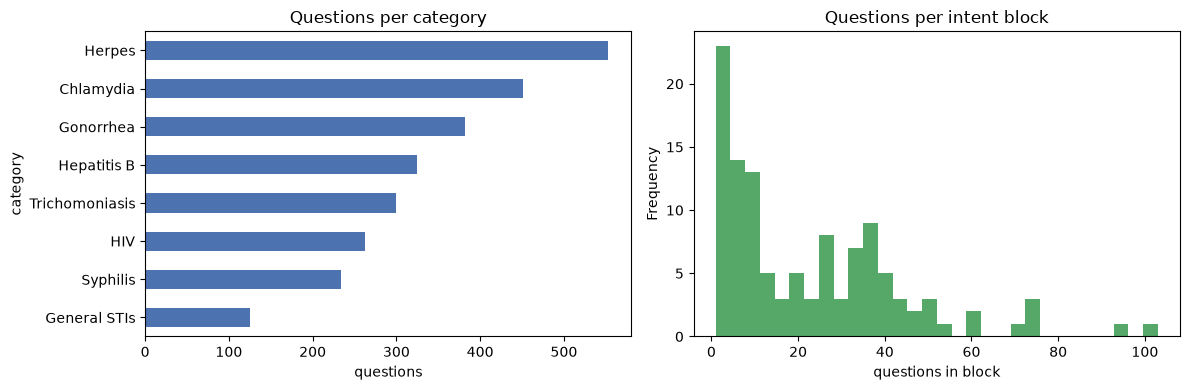

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary.drop("TOTAL")["questions"].sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Questions per category")
axes[0].set_xlabel("questions")
blocks["questions"].plot.hist(ax=axes[1], bins=30, color="#55A868")
axes[1].set_title("Questions per intent block")
axes[1].set_xlabel("questions in block")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/questions_per_category_and_intent.png", dpi=150)
plt.show()

## 6. Answer lengths (words): simple vs long

In [15]:
lengths = pd.DataFrame({
    "simple_answer": raw["simple_answer"].dropna().astype(str).str.split().str.len().reset_index(drop=True),
    "long_answer": raw["long_answer"].dropna().astype(str).str.split().str.len().reset_index(drop=True),
})
q_len = q["question"].astype(str).str.split().str.len()
print("Question length (words):")
print(q_len.describe().round(1).to_string(), end="\n\n")
lengths.describe().round(1)

Question length (words):
count    2631.0
mean        7.0
std         3.9
min         0.0
25%         5.0
50%         7.0
75%         8.0
max        92.0



,simple_answer,long_answer
count,381.0,337.0
mean,48.1,79.8
std,44.4,65.9
min,2.0,4.0
25%,20.0,39.0
50%,37.0,59.0
75%,64.0,97.0
max,490.0,482.0


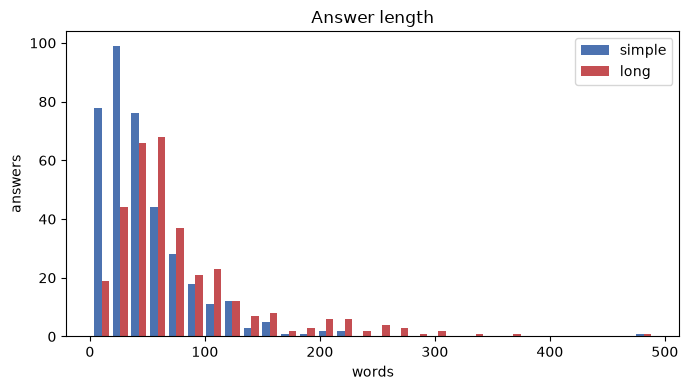

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist([lengths["simple_answer"].dropna(), lengths["long_answer"].dropna()], bins=30,
        label=["simple", "long"], color=["#4C72B0", "#C44E52"])
ax.set_xlabel("words"); ax.set_ylabel("answers"); ax.legend(); ax.set_title("Answer length")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/answer_lengths.png", dpi=150)
plt.show()

## 7. Exact duplicate questions
Compared after lower-casing, removing punctuation and extra spaces.

In [17]:
def normalise(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)   # drop punctuation
    return " ".join(text.split())               # collapse spaces

q["norm"] = q["question"].map(normalise)
dups = q[q.duplicated("norm", keep=False)]
groups = dups.groupby("norm").agg(
    copies=("question", "size"),
    intents=("intent_block", lambda s: sorted(set(s))),
    categories=("category", lambda s: sorted(set(s))),
)
groups["same_intent"] = groups["intents"].str.len() == 1
print("Questions that appear more than once:", groups.shape[0], "distinct texts,", len(dups), "cells")
print("  ...always under the same intent    :", groups["same_intent"].sum())
print("  ...under DIFFERENT intents         :", (~groups["same_intent"]).sum())
groups[~groups["same_intent"]].head(30)

Questions that appear more than once: 140 distinct texts, 284 cells
  ...always under the same intent    : 121
  ...under DIFFERENT intents         : 19


,copies,intents,categories,same_intent
norm,,,,
any types,2,"[types_stis, types_syphilis]","[General STIs, Syphilis]",False
are the risks for getting hiv higher for one engaging in anal sex as compared to vaginal intercourse,2,"[Transmission/Spread_hiv, risk_hiv]",[HIV],False
can i get gonorrhea from close contact,2,"[Transmission/Spread_gonorrhea, Transmission/Spread_gonorrhea_No]",[Gonorrhea],False
can i get gonorrhea from dubbing,2,"[Transmission/Spread_gonorrhea, Transmission/Spread_gonorrhea_No]",[Gonorrhea],False
can i get gonorrhea through fingering,2,"[Transmission/Spread_gonorrhea, Transmission/Spread_gonorrhea_Yes]",[Gonorrhea],False
can i give my girlfriend oral sex if i have chlamydia,2,"[Transmission_spread_chlamydia, safe_sex_practices_chlamydia]",[Chlamydia],False
can i touch someone and get gonorrhea,2,"[Transmission/Spread_gonorrhea, Transmission/Spread_gonorrhea_No]",[Gonorrhea],False
can you be immune to chlamydia,2,"[Education_chlamydia, safe_sex_practices_chlamydia]",[Chlamydia],False
do certain sex styles expose you to hiv more than others,2,"[Transmission/Spread_hiv, risk_hiv]",[HIV],False


## 8. Near-duplicate questions
TF-IDF on character 3–5-grams, then cosine similarity between every pair of questions.
Pairs ≥ 0.9 are near-identical (typos, punctuation, one word changed).

In [18]:
unique_q = q.drop_duplicates("norm").reset_index(drop=True)
vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit_transform(unique_q["norm"])
sim = cosine_similarity(vectors)
np.fill_diagonal(sim, 0)

i, j = np.where(np.triu(sim) >= 0.9)
near = pd.DataFrame({
    "question_a": unique_q.loc[i, "question"].values,
    "question_b": unique_q.loc[j, "question"].values,
    "similarity": sim[i, j].round(3),
    "intent_a": unique_q.loc[i, "intent_block"].values,
    "intent_b": unique_q.loc[j, "intent_block"].values,
})
near["same_intent"] = near["intent_a"] == near["intent_b"]
print("Near-duplicate pairs (>= 0.9):", len(near), "| same intent:", near["same_intent"].sum())
near.sort_values("similarity", ascending=False).head(15)

Near-duplicate pairs (>= 0.9): 731 | same intent: 377


,question_a,question_b,similarity,intent_a,intent_b,same_intent
714,How can I protect Trich from myself?,How can I protect myself from Trich?,1.000,prevention_trichomoniasis,prevention_trichomoniasis,True
613,How can I protect Genital Herpes from myself?,How can I protect myself from Genital Herpes?,1.000,prevention_infections,prevention_infections,True
610,How can I protect HSV from myself?,How can I protect myself from HSV?,1.000,prevention_infections,prevention_infections,True
609,How can I protect Herpes Simplex Virus from myself?,How can I protect myself from Herpes Simplex Virus?,1.000,prevention_infections,prevention_infections,True
710,How can I protect Trichomoniasis from myself.,How can I protect myself from Trichomoniasis?,1.000,prevention_trichomoniasis,prevention_trichomoniasis,True
607,How can I protect Herpes from myself?,How can I protect myself from Herpes?,1.000,prevention_infections,prevention_infections,True
62,Chlamydial Genitourinary Infections transmission?,Transmission of Chlamydial Genitourinary Infections?,0.997,Transmission_spread_chlamydia,Transmission_spread_chlamydia,True
326,Types of Human Immunodeficiency Virus.,Human Immunodeficiency Virus Types.,0.995,types_hiv,types_hiv,True
128,Chlamydial Genitourinary Infection testing?,Testing of Chlamydial Genitourinary Infection?,0.995,testing_chlamydia,testing_chlamydia,True
412,How would you define Hepatitis B?,How would you define a Hepatitis B?,0.994,definition_hepatitis,definition_hepatitis,True


In [19]:
# Near-duplicates under DIFFERENT intents: these are label conflicts
near[~near["same_intent"]].head(20)

,question_a,question_b,similarity,intent_a,intent_b,same_intent
2,What are Chlamydial Genitourinary Infections?,What are the types of Chlamydial Genitourinary Infections?,0.914,definition_chlamydia,types_chlamydia,False
3,What are Chlamydial Genitourinary Infections?,What are the forms of Chlamydial Genitourinary Infections?,0.917,definition_chlamydia,types_chlamydia,False
4,What are Chlamydial Genitourinary Infections?,What are the signs of Chlamydial Genitourinary Infections?,0.921,definition_chlamydia,Symptoms_Chlamydia,False
5,What are Chlamydial Genitourinary Infections?,How can I get Chlamydial Genitourinary Infections?,0.902,definition_chlamydia,Transmission_spread_chlamydia,False
9,What is Chlamydial Genitourinary Infection?,How do I get Chlamydial Genitourinary Infection?,0.908,definition_chlamydia,Transmission_spread_chlamydia,False
11,Chlamydial Genitourinary Infection?,Signs of Chlamydial Genitourinary Infection?,0.919,definition_chlamydia,Symptoms_Chlamydia,False
12,Chlamydial Genitourinary Infection?,How do I get Chlamydial Genitourinary Infection?,0.936,definition_chlamydia,Transmission_spread_chlamydia,False
15,Where did chlamydia originally come from?,Where did HIV originally come from?,0.905,origin_chlamydia,origin_hiv,False
16,Where did chlamydia originally come from?,Where did HBV originally come from?,0.903,origin_chlamydia,origin_hepatitis,False
43,"I have difficulty in urination, do I have chlamydia?","I have difficulty in urination, do I have Gonorrhea?",0.901,Symptoms_Chlamydia,symptoms_Signs_gonorrhea,False


## 9. Personal / demographic columns

In [20]:
all_headers = sorted({h for df in sheets.values() for h in df.columns})
print("All column headers in the file:")
for h in all_headers:
    print(" -", h)

All column headers in the file:
 - Another Questions (the different ways the same question can be asked)
 - Chlamydia_Chatbot_Intents
 - Gonorrhea_Chatbot_Intents
 - HIV_Chatbot_Intents
 - Hepatitis_Chatbot_Intents
 - Herpes_simplex_virus_Chatbot Intents
 - Long Answer
 - Question from Crowdsourcing
 - Questions from Crowdsourcing
 - STIs_Chatbot_Intents
 - Simple Answer
 - Syphilis Chatbot Intents
 - Trichomoniasis Chatbot Intents
 - Unnamed: 1


## 10. Summary of findings (fill in after reading the outputs)
| Check | Result |
|---|---|
| Question cells (vs 5,488 claimed) | |
| Intent blocks | |
| Blocks with exactly 1 simple + 1 long answer | |
| Personal/demographic columns | |
| Duplicate questions under different intents | |

**Decision needed before Phase 2:** what is the label (the "intent") the model predicts,
given that many blocks hold several different answers?